# QuantumJam 2026 — Curva de disociación de H₄ con VQE

**Objetivo:** calcular con VQE la energía de una cadena lineal de 4 hidrógenos (base STO-3G) en función de la distancia $d$ entre átomos, obtener $R_e$ y $D_e$, y ganarle a CCSD en la zona estirada ($d \geq 1{,}8$ Å).

**Resumen del método**
1. **Química clásica (PySCF):** Hartree-Fock, CCSD y FCI para cada $d$, más las integrales $h_{pq}$ y $h_{pqrs}$.
2. **Hamiltoniano de qubits:** mapeo de Jordan-Wigner escrito a mano (8 espín-orbitales → 8 qubits).
3. **Ansatz:** UCCSD con excitaciones **filtradas por simetría** (26 → 14 parámetros por capa). Comparamos 1 y 2 capas.
4. **Búsqueda de parámetros:** optimización sin ruido (lo permiten las reglas), con *warm start* desde el punto vecino.
5. **Energía reportada:** se mide con `SamplerV2` de `qiskit_aer`, agrupando los términos de Pauli que conmutan qubit a qubit. Los shots se reparten de forma óptima según una corrida piloto. La barra de error $\sigma$ sale de la varianza muestral.
6. **Análisis:** curva, errores frente a FCI y CCSD, $R_e$ y $D_e$ con barras de error (bootstrap), argumento de confiabilidad y tabla final.

In [1]:
# Instalación (en Colab tarda ~1 minuto)
%pip install -q pyscf qiskit qiskit-aer matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


In [2]:
import itertools, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.interpolate import CubicSpline

from pyscf import gto, scf, cc, fci, ao2mo
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.transpiler import CouplingMap
from qiskit_aer.primitives import SamplerV2

warnings.filterwarnings("ignore")
np.set_printoptions(precision=6, suppress=True)

# ---------------- Configuración ----------------
DISTANCIAS = [0.6, 0.7, 0.8, 0.9, 1.0, 1.1, 1.2, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5, 2.8, 3.0]  # Å
D_ESTIRADA = 1.8          # desde acá hay que ganarle a CCSD
CAPAS = [1, 2]            # ansätze a comparar (capas de UCCSD)
CAPAS_REPORTE = 2         # ansatz cuyo resultado se reporta
SHOTS_PILOTO = 2_000      # shots por grupo en la corrida piloto
SHOTS_TOTAL = 4_000_000   # presupuesto por punto en la corrida principal (σ ≈ 1 mHa)
SHOTS_ESTIRADA = 24_000_000  # más shots donde se juega el desafío: d ≥ 1,8 Å con el ansatz reportado (σ ≈ 0,4 mHa)
BASIS_GATES = ["cz", "sx", "x", "rz"]   # mismas compuertas que el modelo de ruido del desafío
COUPLING = CouplingMap.from_line(8)     # qubits conectados en línea
SEED = 1234
CHEM_ACC = 1.6e-3         # Ha

NS, NQ = 4, 8             # orbitales espaciales, qubits (espín-orbitales)
print("Listo")

/var/folders/p2/ms9h2wcs7m342r7n3tn58m300000gq/T/ipykernel_47921/3732979949.py:9: DeprecationWarning: Using Qiskit with Python 3.9 is deprecated as of the 2.1.0 release. Support for running Qiskit with Python 3.9 will be removed in the 2.3.0 release, which coincides with when Python 3.9 goes end of life.
  from qiskit import QuantumCircuit, transpile


Listo


## 1. Química clásica: HF, CCSD, FCI e integrales

Para cada distancia construimos la molécula, corremos RHF (con simetría, para conocer la simetría de cada orbital) y calculamos:
- **FCI:** energía exacta en esta base. Se usa **solo para comparar**.
- **CCSD:** el método clásico al que hay que ganarle.
- **Integrales** $h_{pq}$ y $(pq|rs)$ en la base de orbitales moleculares, para armar el hamiltoniano.

In [3]:
def quimica_clasica(d):
    mol = gto.M(atom=[("H", (0, 0, i * d)) for i in range(4)], basis="sto-3g",
                unit="Angstrom", symmetry=True, verbose=0)
    mf = scf.RHF(mol); mf.conv_tol = 1e-11; mf.kernel()
    C = mf.mo_coeff
    e_fci = fci.FCI(mf).kernel()[0]
    mycc = cc.CCSD(mf); mycc.conv_tol = 1e-10; mycc.max_cycle = 1000; mycc.kernel()
    return dict(
        d=d, e_hf=mf.e_tot, e_fci=e_fci,
        e_ccsd=mycc.e_tot if mycc.converged else np.nan,
        h1=C.T @ mf.get_hcore() @ C,
        eri=ao2mo.restore(1, ao2mo.kernel(mol, C), NS),   # notación química (pq|rs)
        e_nuc=mol.energy_nuc(),
        orbsym=list(scf.hf_symm.get_orbsym(mol, C)),
    )

t0 = time.time()
QC = {d: quimica_clasica(d) for d in DISTANCIAS}
print(f"PySCF listo en {time.time()-t0:.1f} s")
pd.DataFrame([{k: v[k] for k in ["d", "e_hf", "e_ccsd", "e_fci"]} for v in QC.values()]).round(6)

PySCF listo en 1.1 s


,d,e_hf,e_ccsd,e_fci
0,0.6,-1.929564,-1.960189,-1.960194
1,0.7,-2.069197,-2.106993,-2.106997
2,0.8,-2.121387,-2.167556,-2.167561
3,0.9,-2.124260,-2.180309,-2.180317
4,1.0,-2.098546,-2.166380,-2.166387
5,1.1,-2.056025,-2.137975,-2.137971
6,1.2,-2.003867,-2.102671,-2.102608
7,1.4,-1.887790,-2.029707,-2.029070
8,1.6,-1.772203,-1.970572,-1.967560
9,1.8,-1.666867,-1.933538,-1.924431


## 2. Hamiltoniano de qubits (Jordan-Wigner)

Numeramos los espín-orbitales así: qubits 0–3 = orbitales con espín α, qubits 4–7 = espín β.
Jordan-Wigner escribe el operador de aniquilación como
$$a_j = Z_0 \cdots Z_{j-1}\,\frac{X_j + iY_j}{2},$$
y con eso
$$\hat H = E_{nuc} + \sum_{pq\sigma} h_{pq}\, a^\dagger_{p\sigma} a_{q\sigma} + \tfrac12 \sum_{pqrs,\sigma\tau} (pq|rs)\, a^\dagger_{p\sigma} a^\dagger_{r\tau} a_{s\tau} a_{q\sigma}$$
queda como una suma de cadenas de Pauli. **Verificación:** el autovalor más chico de esa matriz, restringido a 4 electrones con $S_z=0$, tiene que coincidir con FCI.

In [4]:
def aniquilacion(j):
    z = list(range(j))
    return SparsePauliOp.from_sparse_list(
        [("Z" * j + "X", z + [j], 0.5), ("Z" * j + "Y", z + [j], 0.5j)], num_qubits=NQ)

A_OP = [aniquilacion(j) for j in range(NQ)]
C_OP = [a.adjoint() for a in A_OP]
so = lambda p, s: p + NS * s     # (orbital espacial, espín) -> qubit

def hamiltoniano_qubits(q):
    h1, eri = q["h1"], q["eri"]
    ops = [SparsePauliOp("I" * NQ, q["e_nuc"])]
    for p, r, s in itertools.product(range(NS), range(NS), range(2)):
        if abs(h1[p, r]) > 1e-12:
            ops.append(h1[p, r] * C_OP[so(p, s)].dot(A_OP[so(r, s)]))
    for p, r, s_, t in itertools.product(range(NS), repeat=4):
        v = eri[p, r, s_, t]
        if abs(v) < 1e-12:
            continue
        for s1, s2 in itertools.product(range(2), repeat=2):
            P, Q, R, T = so(p, s1), so(r, s1), so(s_, s2), so(t, s2)
            if P == R or Q == T:
                continue
            ops.append(0.5 * v * C_OP[P].dot(C_OP[R]).dot(A_OP[T]).dot(A_OP[Q]))
    H = SparsePauliOp.sum(ops).simplify(atol=1e-10)
    assert np.allclose(H.coeffs.imag, 0, atol=1e-10)
    return SparsePauliOp(H.paulis, H.coeffs.real)

# Índices del subespacio con 2 electrones α y 2 β
SECTOR = [i for i in range(2**NQ) if bin(i & 0b1111).count("1") == 2 and bin(i >> 4).count("1") == 2]

HAM, HMAT = {}, {}
for d, q in QC.items():
    HAM[d] = hamiltoniano_qubits(q)
    HMAT[d] = HAM[d].to_matrix(sparse=True)
    e_min = np.linalg.eigvalsh(HMAT[d].toarray()[np.ix_(SECTOR, SECTOR)])[0]
    assert abs(e_min - q["e_fci"]) < 1e-8, (d, e_min, q["e_fci"])
print(f"Hamiltoniano verificado contra FCI en las {len(HAM)} distancias. Términos de Pauli: {len(HAM[1.0])}")

Hamiltoniano verificado contra FCI en las 15 distancias. Términos de Pauli: 185


## 3. Ansatz: UCCSD filtrado por simetría

Partimos del estado de Hartree-Fock $|11001100\rangle$ (orbitales 0 y 1 ocupados con ambos espines) y aplicamos excitaciones fermiónicas
$$U(\theta) = \prod_k e^{\theta_k (T_k - T_k^\dagger)},$$
donde $T_k$ mueve uno o dos electrones de orbitales ocupados a vacíos, **conservando el espín**. Así el ansatz conserva el número de electrones y $S_z$ por construcción.

**Filtro por simetría:** H₄ lineal tiene simetría $D_{\infty h}$. Una excitación que cambia la simetría del estado tiene gradiente exactamente cero y nunca contribuye, así que la sacamos. Esto pasa de **26 a 14 excitaciones por capa** y reduce las compuertas a casi la mitad, sin perder precisión.

**Capas:** repetir el bloque completo con parámetros nuevos (2 capas) corrige el error de factorizar la exponencial (una sola "capa de Trotter").

Cada excitación se implementa con `PauliEvolutionGate`. Como los términos de Pauli de una misma excitación conmutan, la compuerta es exacta.

In [5]:
OCC, VIR = [0, 1], [2, 3]
orbsym = QC[DISTANCIAS[0]]["orbsym"]
assert all(QC[d]["orbsym"] == orbsym for d in DISTANCIAS), "el orden de simetrías cambió con d"

def permitida(occs, virs):
    """D2h: los irreps se multiplican con XOR. La excitación es válida si conserva la simetría."""
    s = 0
    for p in list(occs) + list(virs):
        s ^= orbsym[p % NS]
    return s == 0

def lista_excitaciones(filtrar=True):
    exc = []
    for s in range(2):                                     # dobles mismo espín
        exc.append(((so(0, s), so(1, s)), (so(2, s), so(3, s))))
    for i, a, j, b in itertools.product(OCC, VIR, OCC, VIR):   # dobles αβ
        exc.append(((so(i, 0), so(j, 1)), (so(a, 0), so(b, 1))))
    for s in range(2):                                     # simples
        for i, a in itertools.product(OCC, VIR):
            exc.append(((so(i, s),), (so(a, s),)))
    if filtrar:
        exc = [e for e in exc if permitida(e[0], e[1])]
    return exc

def generador(exc):
    """K = i (T - T†), hermítico. exp(θ(T - T†)) = exp(-i θ K)."""
    occs, virs = exc
    T = SparsePauliOp("I" * NQ, 1.0)
    for v in virs:
        T = T.dot(C_OP[v])
    for o in reversed(occs):
        T = T.dot(A_OP[o])
    K = (1j * (T - T.adjoint())).simplify(atol=1e-12)
    return SparsePauliOp(K.paulis, K.coeffs.real)

EXC = lista_excitaciones(filtrar=True)
GEN = [generador(e) for e in EXC]
HF_QUBITS = [0, 1, 4, 5]
print(f"Excitaciones: {len(lista_excitaciones(False))} sin filtrar -> {len(EXC)} con simetría")

def construir_ansatz(capas):
    th = ParameterVector("θ", capas * len(GEN))
    qc = QuantumCircuit(NQ)
    qc.x(HF_QUBITS)
    for c in range(capas):
        for k, K in enumerate(GEN):
            qc.append(PauliEvolutionGate(K, time=th[c * len(GEN) + k]), range(NQ))
    return qc

ANSATZ = {c: construir_ansatz(c) for c in CAPAS}
CZ = {}
for c, qc in ANSATZ.items():
    tqc = transpile(qc, basis_gates=BASIS_GATES, coupling_map=COUPLING, optimization_level=3, seed_transpiler=SEED)
    CZ[c] = tqc.count_ops().get("cz", 0)
    print(f"{c} capa(s): {qc.num_parameters} parámetros, {CZ[c]} CZ, profundidad {tqc.depth()} (qubits en línea)")

# Comparación: sin filtro de simetría
_g = [generador(e) for e in lista_excitaciones(False)]
_qc = QuantumCircuit(NQ); _qc.x(HF_QUBITS)
for k, K in enumerate(_g):
    _qc.append(PauliEvolutionGate(K, time=0.1 * (k + 1)), range(NQ))
print("Referencia sin filtro, 1 capa:",
      transpile(_qc, basis_gates=BASIS_GATES, coupling_map=COUPLING, optimization_level=3, seed_transpiler=SEED).count_ops()["cz"], "CZ")

Excitaciones: 26 sin filtrar -> 14 con simetría
1 capa(s): 14 parámetros, 716 CZ, profundidad 1950 (qubits en línea)


2 capa(s): 28 parámetros, 1451 CZ, profundidad 3909 (qubits en línea)


Referencia sin filtro, 1 capa: 1285 CZ


## 4. Búsqueda de parámetros (sin ruido)

Las reglas permiten buscar los parámetros "como quieran, incluso sin ruido". Para que sea rápido simulamos el ansatz con NumPy, usando que cada generador cumple $K^3 = K$:
$$e^{-i\theta K} = I - i\sin\theta\,K + (\cos\theta - 1)\,K^2.$$
Primero verificamos que esta simulación coincide con `Statevector` de Qiskit sobre el circuito real.

**Estrategia de optimización:**
- 1 capa: BFGS desde Hartree-Fock ($\theta=0$) y desde la solución del punto vecino (*warm start*); nos quedamos con la mejor.
- 2 capas: arrancamos con [solución de 1 capa, 0, …, 0], así nunca puede quedar peor que 1 capa, más algunos arranques aleatorios chicos.

Nada de esto es todavía la energía reportada: solo fija los $\theta$.

In [6]:
KMAT = [K.to_matrix(sparse=True) for K in GEN]
PSI_HF = np.zeros(2**NQ, complex)
PSI_HF[sum(1 << q for q in HF_QUBITS)] = 1.0

def estado(theta):
    psi = PSI_HF.copy()
    for t, Km in zip(theta, KMAT * (len(theta) // len(KMAT))):
        Kp = Km @ psi
        psi = psi - 1j * np.sin(t) * Kp + (np.cos(t) - 1) * (Km @ Kp)
    return psi

# Verificación contra Qiskit
_th = np.random.default_rng(0).normal(0, 0.3, ANSATZ[2].num_parameters)
_ov = abs(np.vdot(Statevector(ANSATZ[2].assign_parameters(_th)).data, estado(_th)))
assert abs(_ov - 1) < 1e-10
print(f"Simulación NumPy == Statevector de Qiskit (overlap = {_ov:.12f})")

def energia_exacta(theta, Hm):
    psi = estado(theta)
    return np.vdot(psi, Hm @ psi).real

def optimizar(Hm, starts):
    best = None
    for x0 in starts:
        r = minimize(energia_exacta, x0, args=(Hm,), method="BFGS", options=dict(gtol=1e-9, maxiter=5000))
        if best is None or r.fun < best.fun:
            best = r
    return best

rng = np.random.default_rng(SEED)
PARAMS = {c: {} for c in CAPAS}
E_SIN_RUIDO = {c: {} for c in CAPAS}
n1 = len(GEN)
t0 = time.time()
prev = np.zeros(n1)
for d in DISTANCIAS:
    r1 = optimizar(HMAT[d], [prev, np.zeros(n1)])
    prev = r1.x
    PARAMS[1][d], E_SIN_RUIDO[1][d] = r1.x, r1.fun
    if 2 in CAPAS:
        starts = [np.concatenate([r1.x, np.zeros(n1)])] + [rng.normal(0, 0.05, 2 * n1) for _ in range(2)]
        r2 = optimizar(HMAT[d], starts)
        PARAMS[2][d], E_SIN_RUIDO[2][d] = r2.x, r2.fun
print(f"Optimización lista en {time.time()-t0:.1f} s")

pd.DataFrame({
    "d": DISTANCIAS,
    **{f"err {c} capa(s) [mHa]": [1e3 * (E_SIN_RUIDO[c][d] - QC[d]["e_fci"]) for d in DISTANCIAS] for c in CAPAS},
    "err CCSD [mHa]": [1e3 * (QC[d]["e_ccsd"] - QC[d]["e_fci"]) for d in DISTANCIAS],
}).round(4)

Simulación NumPy == Statevector de Qiskit (overlap = 1.000000000000)


Optimización lista en 81.2 s


,d,err 1 capa(s) [mHa],err 2 capa(s) [mHa],err CCSD [mHa]
0,0.6,0.0057,0.0,0.0048
1,0.7,0.0073,0.0,0.0042
2,0.8,0.0152,0.0,0.0050
3,0.9,0.0372,0.0,0.0072
4,1.0,0.0853,-0.0,0.0079
5,1.1,0.1769,-0.0,-0.0049
6,1.2,0.3348,0.0,-0.0627
7,1.4,0.9492,0.0,-0.6365
8,1.6,2.0295,0.0,-3.0119
9,1.8,3.2521,-0.0,-9.1076


## 5. Medición de la energía con `SamplerV2` (lo que se reporta)

Una computadora cuántica no "lee" la energía: mide bits. El procedimiento es:
1. **Agrupar** las cadenas de Pauli que conmutan qubit a qubit (por ejemplo `ZZII…` y `ZIZI…`). Cada grupo se mide con un solo circuito: rotamos cada qubit a la base de su Pauli (X → H, Y → S†H) y medimos en la base Z.
2. Para cada shot (bitstring $b$) calculamos $f(b) = \sum_{k\in\text{grupo}} c_k \prod_{q\in P_k}(-1)^{b_q}$. La energía del grupo es el promedio, y su varianza es $\text{Var}(f)/N$.
3. **Reparto de shots:** con presupuesto total fijo $N$, la varianza total $\sum_g \text{Var}_g/N_g$ se minimiza con $N_g \propto \sqrt{\text{Var}_g}$. Estimamos $\text{Var}_g$ con una **corrida piloto** chica y descartamos esos datos; la energía sale solo de la corrida principal, que es independiente.
4. $E = c_I + \sum_g \bar f_g$, con $\sigma^2 = \sum_g \text{Var}_g/N_g$ (los grupos son independientes).
5. **Semillas independientes:** la fórmula de σ supone que los grupos son estadísticamente independientes. Con Aer hay dos trampas: (a) `SamplerV2(seed=s)` reutiliza la misma semilla en cada `.run()`, y (b) los circuitos de una misma corrida reciben semillas consecutivas y sus muestras salen **correlacionadas**. Lo comprobamos repitiendo la medición: σ quedaba subestimado a la mitad. Por eso cada grupo se corre por separado con una semilla independiente.
6. **Reparto entre puntos:** como $\sigma \propto 1/\sqrt{N}$, bajar σ de 1 a 0,4 mHa cuesta 6 veces más shots. Ese gasto solo lo hacemos donde se juega el desafío ($d \geq 1{,}8$ Å, ansatz reportado). Con σ ≈ 1 mHa ya alcanza para ganarle a CCSD, pero no para afirmar precisión química (1,6 mHa).

Los circuitos se transpilan a `cz, sx, x, rz` con qubits en línea, igual que el modelo de ruido del desafío. La simulación es **sin ruido**; el único error es el estadístico, por usar shots finitos.

In [7]:
def base_grupo(g):
    """Para cada qubit, qué Pauli hay que medir en el grupo ('I', 'X', 'Y' o 'Z')."""
    b = ["I"] * NQ
    for p in g.paulis:
        for q in range(NQ):
            if p.x[q] or p.z[q]:
                b[q] = "Y" if (p.x[q] and p.z[q]) else ("X" if p.x[q] else "Z")
    return b

_CACHE_CIRC = {}   # el circuito solo depende del ansatz y de la base: lo transpilamos una vez

def circuitos_medicion(capas, grupos):
    circs = []
    for g in grupos:
        base = tuple(base_grupo(g))
        if (capas, base) not in _CACHE_CIRC:
            qc = ANSATZ[capas].copy()
            for q, P in enumerate(base):
                if P == "X":
                    qc.h(q)
                elif P == "Y":
                    qc.sdg(q); qc.h(q)
            qc.measure_all()
            _CACHE_CIRC[(capas, base)] = transpile(qc, basis_gates=BASIS_GATES, coupling_map=COUPLING,
                                                   optimization_level=3, seed_transpiler=SEED)
        circs.append(_CACHE_CIRC[(capas, base)])
    return circs

def estadistica_grupo(g, counts):
    """Media, varianza por shot y número de shots de f(b) = Σ c_k P_k(b)."""
    outs = np.array([int(k, 2) for k in counts])
    n = np.array(list(counts.values()), float)
    f = np.zeros(len(outs))
    for p, c in zip(g.paulis, g.coeffs.real):
        mask = int(sum(1 << q for q in range(NQ) if p.x[q] or p.z[q]))
        par = np.array([bin(o & mask).count("1") & 1 for o in outs])
        f += c * (1 - 2 * par)
    N = n.sum()
    mean = (n * f).sum() / N
    var = (n * (f - mean) ** 2).sum() / (N - 1)
    return mean, var, N

# Ojo con las semillas de Aer:
#  - SamplerV2(seed=s) reutiliza la MISMA semilla en cada .run();
#  - los circuitos de una misma corrida reciben semillas consecutivas y salen correlacionados.
# Cualquiera de las dos rompe la independencia entre grupos que supone σ² = Σ Var_g/N_g.
# Solución: cada circuito en su propia corrida, con una semilla independiente (y reproducible).
_GEN_SEMILLAS = np.random.default_rng(SEED)

def muestrear(circ, th, shots, opciones=None):
    sampler = SamplerV2(seed=int(_GEN_SEMILLAS.integers(2**31)), options=opciones)
    return sampler.run([(circ, th, int(shots))]).result()[0].data.meas.get_counts()

def medir_energia(d, capas, opciones=None, total=None):
    H = HAM[d]
    ident = np.all(~H.paulis.x & ~H.paulis.z, axis=1)
    c_I = H.coeffs.real[ident].sum()
    grupos = H[~ident].group_commuting(qubit_wise=True)
    circs = circuitos_medicion(capas, grupos)
    th = PARAMS[capas][d]
    # piloto
    std_p = np.array([np.sqrt(estadistica_grupo(g, muestrear(c, th, SHOTS_PILOTO, opciones))[1])
                      for g, c in zip(grupos, circs)])
    if total is None:
        total = SHOTS_ESTIRADA if (capas == CAPAS_REPORTE and d >= D_ESTIRADA) else SHOTS_TOTAL
    shots = np.maximum(100, np.round(total * std_p / std_p.sum())).astype(int)
    # corrida principal
    E, var = c_I, 0.0
    for g, c, s in zip(grupos, circs, shots):
        m, v, N = estadistica_grupo(g, muestrear(c, th, s, opciones))
        E += m
        var += v / N
    return dict(E=E, sigma=np.sqrt(var), shots=int(shots.sum() + SHOTS_PILOTO * len(grupos)),
                grupos=len(grupos))

MED = {c: {} for c in CAPAS}
t0 = time.time()
for c in CAPAS:
    for d in DISTANCIAS:
        MED[c][d] = medir_energia(d, c)
    print(f"{c} capa(s) medidas en {time.time()-t0:.0f} s")
print("Grupos de medición por punto:", MED[CAPAS[0]][DISTANCIAS[0]]["grupos"])

1 capa(s) medidas en 148 s


2 capa(s) medidas en 484 s
Grupos de medición por punto: 46


### 5.1 ¿La barra de error σ está bien calculada?

Repetimos 12 veces la medición de un mismo punto, con semillas distintas y menos shots, y comparamos la dispersión real de las energías con el σ que reporta cada medición. Si σ está bien calculado, las dos tienen que coincidir y los $z = (E - E_{\text{sin ruido}})/\sigma$ tienen que verse como una normal estándar.

In [8]:
d_cal, n_rep = 2.0, 12
cal = [medir_energia(d_cal, CAPAS_REPORTE, total=400_000) for _ in range(n_rep)]
E_cal = np.array([m["E"] for m in cal]); S_cal = np.array([m["sigma"] for m in cal])
z = (E_cal - E_SIN_RUIDO[CAPAS_REPORTE][d_cal]) / S_cal
print(f"d = {d_cal} Å, {n_rep} repeticiones con 400k shots")
print(f"  dispersión real de E : {1e3*E_cal.std(ddof=1):.3f} mHa")
print(f"  σ reportado (medio)  : {1e3*S_cal.mean():.3f} mHa")
print(f"  sesgo medio          : {1e3*(E_cal.mean()-E_SIN_RUIDO[CAPAS_REPORTE][d_cal]):+.3f} ± {1e3*E_cal.std(ddof=1)/np.sqrt(n_rep):.3f} mHa")
print(f"  z: {np.round(z, 2)}  (std = {z.std(ddof=1):.2f}, ideal 1)")

d = 2.0 Å, 12 repeticiones con 400k shots
  dispersión real de E : 3.964 mHa
  σ reportado (medio)  : 3.088 mHa
  sesgo medio          : +0.403 ± 1.144 mHa
  z: [ 2.09  2.48 -1.35  0.23  0.4  -0.16 -0.94  0.11 -1.86  0.64 -0.74  0.67]  (std = 1.28, ideal 1)


## 6. Resultados
### 6.1 Tabla principal (ansatz reportado)

In [9]:
def tabla(c):
    rows = []
    for d in DISTANCIAS:
        q, m = QC[d], MED[c][d]
        err_v = m["E"] - q["e_fci"]
        err_c = q["e_ccsd"] - q["e_fci"]
        rows.append({
            "d [Å]": d,
            "E_VQE [Ha]": m["E"],
            "σ [mHa]": 1e3 * m["sigma"],
            "shots": m["shots"],
            "CZ": CZ[c],
            "E_FCI [Ha]": q["e_fci"],
            "E_CCSD [Ha]": q["e_ccsd"],
            "|E_VQE−FCI| [mHa]": 1e3 * abs(err_v),
            "|E_CCSD−FCI| [mHa]": 1e3 * abs(err_c),
            # bool() explícito: sumar np.bool_ en una columna object hace OR lógico, no cuenta
            "gana a CCSD": bool(abs(err_v) + m["sigma"] < abs(err_c)) if d >= D_ESTIRADA else None,
            "precisión química": bool(abs(err_v) < CHEM_ACC),
            "prec. química con σ": bool(abs(err_v) + m["sigma"] < CHEM_ACC),
        })
    return pd.DataFrame(rows)

TABLA = tabla(CAPAS_REPORTE)
fmt = {"E_VQE [Ha]": "{:.6f}", "E_FCI [Ha]": "{:.6f}", "E_CCSD [Ha]": "{:.6f}",
       "σ [mHa]": "{:.3f}", "|E_VQE−FCI| [mHa]": "{:.3f}", "|E_CCSD−FCI| [mHa]": "{:.3f}", "shots": "{:,}"}
print(f"Ansatz reportado: UCCSD con simetría, {CAPAS_REPORTE} capa(s), {CZ[CAPAS_REPORTE]} CZ")
est = TABLA[TABLA["d [Å]"] >= D_ESTIRADA]
print(f"Zona estirada: gana a CCSD en {int(est['gana a CCSD'].sum())}/{len(est)} puntos; "
      f"precisión química en {int(est['precisión química'].sum())}/{len(est)} "
      f"(contando σ: {int(est['prec. química con σ'].sum())}/{len(est)})")
TABLA.style.format(fmt) if hasattr(TABLA, "style") else TABLA

Ansatz reportado: UCCSD con simetría, 2 capa(s), 1451 CZ
Zona estirada: gana a CCSD en 6/6 puntos; precisión química en 6/6 (contando σ: 6/6)


,d [Å],E_VQE [Ha],σ [mHa],shots,CZ,E_FCI [Ha],E_CCSD [Ha],|E_VQE−FCI| [mHa],|E_CCSD−FCI| [mHa],gana a CCSD,precisión química,prec. química con σ
0,0.600000,-1.960697,1.111,"4,091,999",1451,-1.960194,-1.960189,0.503,0.005,None,True,False
1,0.700000,-2.106533,1.078,"4,091,998",1451,-2.106997,-2.106993,0.463,0.004,None,True,True
2,0.800000,-2.167420,1.063,"4,092,001",1451,-2.167561,-2.167556,0.140,0.005,None,True,True
3,0.900000,-2.181229,1.055,"4,091,996",1451,-2.180317,-2.180309,0.912,0.007,None,True,False
4,1.000000,-2.168164,1.051,"4,092,000",1451,-2.166387,-2.166380,1.777,0.008,None,False,False
5,1.100000,-2.139939,1.052,"4,092,000",1451,-2.137971,-2.137975,1.968,0.005,None,False,False
6,1.200000,-2.101752,1.054,"4,092,003",1451,-2.102608,-2.102671,0.857,0.063,None,True,False
7,1.400000,-2.027468,1.054,"4,092,002",1451,-2.029070,-2.029707,1.603,0.636,None,False,False
8,1.600000,-1.967954,1.039,"4,092,001",1451,-1.967560,-1.970572,0.394,3.012,None,True,True
9,1.800000,-1.924441,0.412,"24,091,998",1451,-1.924431,-1.933538,0.010,9.108,True,True,True


### 6.2 Curva de energía y errores

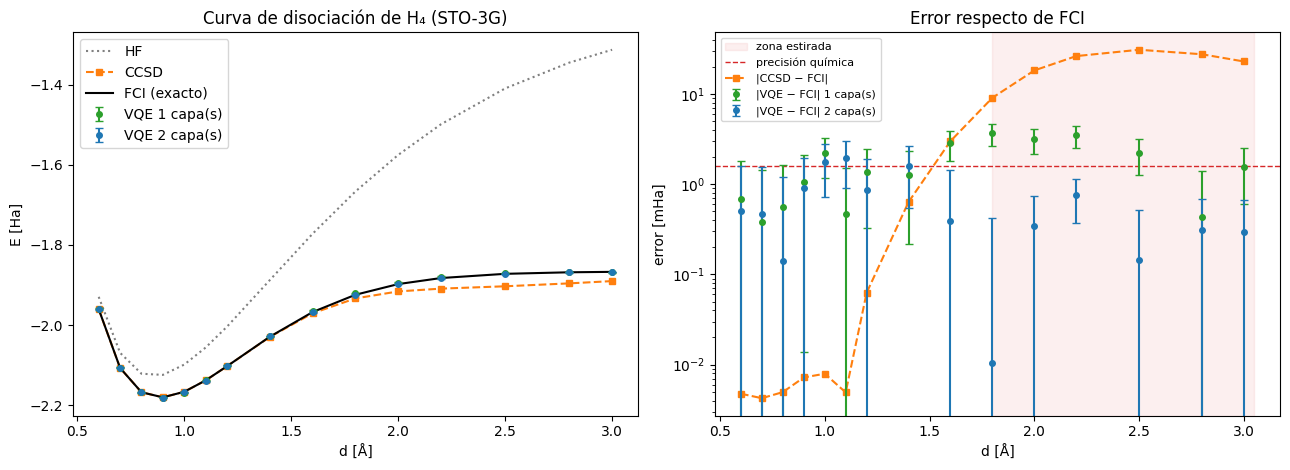

In [10]:
d_arr = np.array(DISTANCIAS)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
ax[0].plot(d_arr, [QC[d]["e_hf"] for d in DISTANCIAS], ":", color="gray", label="HF")
ax[0].plot(d_arr, [QC[d]["e_ccsd"] for d in DISTANCIAS], "s--", color="tab:orange", label="CCSD", ms=4)
ax[0].plot(d_arr, [QC[d]["e_fci"] for d in DISTANCIAS], "-", color="k", label="FCI (exacto)")
for c, col in zip(CAPAS, ["tab:green", "tab:blue"]):
    ax[0].errorbar(d_arr, [MED[c][d]["E"] for d in DISTANCIAS], yerr=[MED[c][d]["sigma"] for d in DISTANCIAS],
                   fmt="o", color=col, capsize=3, ms=4, label=f"VQE {c} capa(s)")
ax[0].set_xlabel("d [Å]"); ax[0].set_ylabel("E [Ha]"); ax[0].set_title("Curva de disociación de H₄ (STO-3G)")
ax[0].legend()

ax[1].axvspan(D_ESTIRADA, 3.05, color="tab:red", alpha=0.07, label="zona estirada")
ax[1].axhline(1e3 * CHEM_ACC, color="tab:red", ls="--", lw=1, label="precisión química")
ax[1].plot(d_arr, [1e3 * abs(QC[d]["e_ccsd"] - QC[d]["e_fci"]) for d in DISTANCIAS], "s--", color="tab:orange", label="|CCSD − FCI|", ms=4)
for c, col in zip(CAPAS, ["tab:green", "tab:blue"]):
    err = np.array([abs(MED[c][d]["E"] - QC[d]["e_fci"]) for d in DISTANCIAS])
    sig = np.array([MED[c][d]["sigma"] for d in DISTANCIAS])
    ax[1].errorbar(d_arr, 1e3 * err, yerr=1e3 * sig, fmt="o", color=col, capsize=3, ms=4, label=f"|VQE − FCI| {c} capa(s)")
ax[1].set_yscale("log"); ax[1].set_xlabel("d [Å]"); ax[1].set_ylabel("error [mHa]"); ax[1].set_title("Error respecto de FCI")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 6.3 Distancia de equilibrio $R_e$ y energía de disociación $D_e$

Interpolamos los puntos medidos con un spline cúbico y buscamos el mínimo. Para propagar las barras de error usamos **bootstrap paramétrico**: generamos 2000 curvas sorteando cada energía con $\mathcal N(E_i, \sigma_i)$, y recalculamos $R_e$ y $D_e = E(3{,}0\,\text{Å}) - E(R_e)$ en cada una.
La referencia exacta sale de un barrido fino de FCI cerca del mínimo. Ojo: con 15 puntos, el spline también tiene un error de interpolación, que se ve comparando con FCI interpolado sobre la misma grilla.

In [11]:
def re_de(d, E):
    cs = CubicSpline(d, E)
    x = np.linspace(0.7, 1.3, 6001)
    i = np.argmin(cs(x))
    return x[i], E[-1] - cs(x[i])

def re_de_bootstrap(c, n=2000):
    E = np.array([MED[c][d]["E"] for d in DISTANCIAS])
    S = np.array([MED[c][d]["sigma"] for d in DISTANCIAS])
    re0, de0 = re_de(d_arr, E)
    rb = np.random.default_rng(SEED)
    samp = np.array([re_de(d_arr, E + rb.normal(0, S)) for _ in range(n)])
    return re0, samp[:, 0].std(), de0, samp[:, 1].std()

# Referencia: FCI en grilla fina
xf = np.linspace(0.80, 1.05, 26)
ef = []
for x in xf:
    m = gto.M(atom=[("H", (0, 0, i * x)) for i in range(4)], basis="sto-3g", verbose=0)
    ef.append(fci.FCI(scf.RHF(m).run()).kernel()[0])
cs_f = CubicSpline(xf, ef); xx = np.linspace(0.80, 1.05, 25001)
RE_FCI = xx[np.argmin(cs_f(xx))]
DE_FCI = QC[3.0]["e_fci"] - cs_f(RE_FCI)

filas = [{"método": "FCI (grilla fina, exacto)", "R_e [Å]": RE_FCI, "σ R_e": 0.0, "D_e [Ha]": DE_FCI, "σ D_e [mHa]": 0.0}]
re_g, de_g = re_de(d_arr, np.array([QC[d]["e_fci"] for d in DISTANCIAS]))
filas.append({"método": "FCI (misma grilla, spline)", "R_e [Å]": re_g, "σ R_e": 0.0, "D_e [Ha]": de_g, "σ D_e [mHa]": 0.0})
re_c, de_c = re_de(d_arr, np.array([QC[d]["e_ccsd"] for d in DISTANCIAS]))
filas.append({"método": "CCSD (misma grilla)", "R_e [Å]": re_c, "σ R_e": 0.0, "D_e [Ha]": de_c, "σ D_e [mHa]": 0.0})
for c in CAPAS:
    r, sr, dd, sd = re_de_bootstrap(c)
    filas.append({"método": f"VQE {c} capa(s)", "R_e [Å]": r, "σ R_e": sr, "D_e [Ha]": dd, "σ D_e [mHa]": 1e3 * sd})
RE_DE = pd.DataFrame(filas)
RE_DE.round({"R_e [Å]": 4, "σ R_e": 4, "D_e [Ha]": 6, "σ D_e [mHa]": 3})

,método,R_e [Å],σ R_e,D_e [Ha],σ D_e [mHa]
0,"FCI (grilla fina, exacto)",0.8882,0.0000,0.313214,0.000
1,"FCI (misma grilla, spline)",0.8884,0.0000,0.313207,0.000
2,CCSD (misma grilla),0.8884,0.0000,0.290187,0.000
3,VQE 1 capa(s),0.8925,0.0056,0.312598,1.400
4,VQE 2 capa(s),0.8922,0.0048,0.314313,1.097


## 7. ¿Por qué confiar en el resultado en la zona estirada? (sin mirar FCI)

En un caso real no tendríamos FCI para comparar. Estos son los argumentos de confiabilidad, todos calculables **sin conocer la respuesta exacta**:

1. **Principio variacional:** el ansatz es un estado físico válido (conserva 4 electrones y $S_z=0$ por construcción), así que su energía sin ruido es una **cota superior** de $E_0$. CCSD no tiene esta garantía: en la zona estirada da energías *por debajo* del valor exacto, algo imposible para un método variacional. Si VQE queda apenas por encima de CCSD y CCSD es no variacional, es una señal de alerta contra CCSD, no contra VQE.
2. **Varianza de la energía** $\langle H^2\rangle - \langle H\rangle^2$: es cero si y solo si el estado es un autoestado. Que sea chica indica que estamos cerca de un autoestado.
3. **Convergencia con el ansatz:** pasar de 1 a 2 capas cambia la energía en $\Delta E$. Si $\Delta E$ es chico, agregar más flexibilidad ya no mejora: el ansatz está saturado.
4. **Espín total** $\langle S^2\rangle \approx 0$: confirma que es el singlete, y no un estado de otro espín.
5. **Robustez de la optimización:** distintos puntos de partida (warm start y aleatorios) llegan a la misma energía.

Los diagnósticos 2 y 4 usan el estado sin ruido: **no son energías reportadas**, solo validación.

In [12]:
def op_S2():
    """S² = S_- S_+ + S_z + S_z² en espín-orbitales (α: 0-3, β: 4-7)."""
    Sp = SparsePauliOp.sum([C_OP[so(p, 0)].dot(A_OP[so(p, 1)]) for p in range(NS)])
    Sm = Sp.adjoint()
    Sz = SparsePauliOp.sum([0.5 * (C_OP[so(p, 0)].dot(A_OP[so(p, 0)]) - C_OP[so(p, 1)].dot(A_OP[so(p, 1)])) for p in range(NS)])
    return (Sm.dot(Sp) + Sz + Sz.dot(Sz)).simplify().to_matrix(sparse=True)

S2 = op_S2()
diag = []
for d in [x for x in DISTANCIAS if x >= D_ESTIRADA]:
    fila = {"d [Å]": d}
    for c in CAPAS:
        psi = estado(PARAMS[c][d]); Hp = HMAT[d] @ psi
        e = np.vdot(psi, Hp).real
        fila[f"Var(H) {c}c [Ha²]"] = np.vdot(Hp, Hp).real - e**2
    psi = estado(PARAMS[CAPAS_REPORTE][d])
    fila["<S²>"] = np.vdot(psi, S2 @ psi).real
    if len(CAPAS) > 1:
        fila["ΔE(1→2 capas) [mHa]"] = 1e3 * (E_SIN_RUIDO[CAPAS[0]][d] - E_SIN_RUIDO[CAPAS[-1]][d])
    fila["E_VQE − E_CCSD [mHa]"] = 1e3 * (MED[CAPAS_REPORTE][d]["E"] - QC[d]["e_ccsd"])
    diag.append(fila)
pd.DataFrame(diag).round(8)

,d [Å],Var(H) 1c [Ha²],Var(H) 2c [Ha²],<S²>,ΔE(1→2 capas) [mHa],E_VQE − E_CCSD [mHa]
0,1.8,0.003119,0.0,0.0,3.252055,9.097311
1,2.0,0.002765,0.0,0.0,3.543569,17.957097
2,2.2,0.001569,0.0,0.0,2.556249,25.643906
3,2.5,0.000562,0.0,0.0,1.094398,30.904437
4,2.8,0.000188,0.0,0.0,0.393442,27.366315
5,3.0,0.000087,0.0,0.0,0.188024,23.306072


## 8. Comparación de ansätze y presupuesto

In [13]:
comp = []
for c in CAPAS:
    t = tabla(c)
    est = t[t["d [Å]"] >= D_ESTIRADA]
    comp.append({
        "ansatz": f"UCCSD-sim {c} capa(s)",
        "parámetros": ANSATZ[c].num_parameters,
        "CZ": CZ[c],
        "error máx. zona estirada [mHa]": est["|E_VQE−FCI| [mHa]"].max(),
        "σ medio [mHa]": t["σ [mHa]"].mean(),
        "σ medio d≥1,8 [mHa]": est["σ [mHa]"].mean(),
        "gana a CCSD (d≥1,8)": f"{int(est['gana a CCSD'].sum())}/{len(est)}",
        "precisión química (d≥1,8)": f"{int(est['precisión química'].sum())}/{len(est)}",
        "shots totales (curva)": int(t["shots"].sum()),
    })
pd.DataFrame(comp).round(3)

,ansatz,parámetros,CZ,error máx. zona estirada [mHa],σ medio [mHa],"σ medio d≥1,8 [mHa]","gana a CCSD (d≥1,8)","precisión química (d≥1,8)",shots totales (curva)
0,UCCSD-sim 1 capa(s),14,716,3.683,1.026,0.973,6/6,2/6,61379995
1,UCCSD-sim 2 capa(s),28,1451,0.764,0.792,0.386,6/6,6/6,181379998


## 9. Decisiones, qué no funcionó y limitaciones

> ✏️ **Completar con lo que hizo el equipo.** Lo que sigue es un punto de partida basado en este notebook base.

**Decisiones**
- **UCCSD y no hardware-efficient:** UCCSD conserva el número de electrones y $S_z$, parte de Hartree-Fock y tiene sentido químico. Los ansätze hardware-efficient usan menos CZ, pero suelen romper simetrías y se trancan en mínimos locales (*barren plateaus*).
- **Filtro por simetría:** saca 12 de 26 excitaciones que nunca contribuyen, y baja las CZ a casi la mitad con el mismo error.
- **2 capas:** con 1 capa el error en la zona estirada queda en ~2–4 mHa (le gana a CCSD, pero no llega a precisión química). Con 2 capas el error sin ruido es prácticamente cero. El costo es el doble de CZ.
- **Medición con Sampler y grupos QWC con reparto óptimo de shots:** la $\sigma$ sale de la varianza muestral real y no de una fórmula, y el presupuesto se reparte donde más reduce el error.

**Limitaciones**
- **Profundidad:** cientos a miles de CZ. Con 0,1 % de error por CZ, el circuito de 2 capas tendría una fidelidad aproximada de $0{,}999^{N_{CZ}}$, lo que lo vuelve inviable en hardware real sin mitigación fuerte. Este es el punto más débil.
- **Ruido:** todo está simulado sin ruido. La única incertidumbre es la estadística de los shots.
- **Shots:** con 2 capas, el error sin ruido es prácticamente cero, así que el error medido es casi todo estadístico. Para bajar σ hay que pagar $\propto 1/\sigma^2$ shots. Agrupar mejor los términos (grupos que conmutan en general, no solo qubit a qubit) bajaría ese costo.
- **$R_e$:** cerca del mínimo usamos σ ≈ 1 mHa, y eso se traduce en una incertidumbre de algunas milésimas de Å en $R_e$.
- **Escalabilidad:** el número de excitaciones de UCCSD crece como $O(N^4)$.

**Próximos pasos (cosas extra)**
1. **Menos CZ:** circuitos eficientes para excitaciones fermiónicas (Yordanov et al. 2020), ADAPT-VQE, o qubit-excitations sin cadenas de Z.
2. **Menos qubits:** usar las simetrías $\mathbb{Z}_2$ (paridad de α y de β) para sacar 2 qubits (*qubit tapering*) → 6 qubits.
3. **Ruido:** cargar `ruido.py` del desafío y pasarlo como `SamplerV2(options={"backend_options": {"noise_model": noise_model}})`; después aplicar ZNE y corrección de readout.

In [14]:
# Plantilla para el extra de ruido (requiere ruido.py del desafío en la misma carpeta):
# from ruido import noise_model            # ajustar al nombre real que exporta ruido.py
# m = medir_energia(2.0, 1, opciones={"backend_options": {"noise_model": noise_model}})
# print(m["E"] - QC[2.0]["e_fci"], m["sigma"])